# Veri Bilimi 101 Proje | Kız Başına Veri Analizi Bootcamp

Gerekli kütüphanelerin içe aktarılması

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt


Veri setinin yüklenmesi

In [2]:
df = pd.read_csv('/kaggle/input/bmw-car-sales-classification-dataset/BMW_Car_Sales_Classification.csv')

İlk ve son satırların görüntülenmesi

In [3]:
df.head()

,Model,Year,Region,Color,Fuel_Type,Transmission,Engine_Size_L,Mileage_KM,Price_USD,Sales_Volume,Sales_Classification
0,5 Series,2016,Asia,Red,Petrol,Manual,3.5,151748,98740,8300,High
1,i8,2013,North America,Red,Hybrid,Automatic,1.6,121671,79219,3428,Low
2,5 Series,2022,North America,Blue,Petrol,Automatic,4.5,10991,113265,6994,Low
3,X3,2024,Middle East,Blue,Petrol,Automatic,1.7,27255,60971,4047,Low
4,7 Series,2020,South America,Black,Diesel,Manual,2.1,122131,49898,3080,Low


In [4]:
df.tail()

,Model,Year,Region,Color,Fuel_Type,Transmission,Engine_Size_L,Mileage_KM,Price_USD,Sales_Volume,Sales_Classification
49995,i3,2014,Asia,Red,Hybrid,Manual,4.6,151030,42932,8182,High
49996,i3,2023,Middle East,Silver,Electric,Manual,4.2,147396,48714,9816,High
49997,5 Series,2010,Middle East,Red,Petrol,Automatic,4.5,174939,46126,8280,High
49998,i3,2020,Asia,White,Electric,Automatic,3.8,3379,58566,9486,High
49999,X1,2020,North America,Blue,Diesel,Manual,3.3,171003,77492,1764,Low


Veri setinin boyutlarının incelenmesi için *df.shape fonksiyonu* kullanılmıştır.

In [5]:
df.shape

(50000, 11)

Veri setinin yapısını ve özelliklerinin incelenmesi için *df.info() fonksiyonu* kullanılmıştır.

* Çıktıya bakıldığında, toplamda 50000 kayıt ve 11 değişken bulunduğu görülmektedir. Kolonlarda eksik veri bulunmakta, her bir değişken 50000 adet geçerli (non-null) değer içermektedir.
* Değişkenlerin veri tiplerine bakıldığında; 6 adet kategorik değişken ve geri kalan 5 adetin ise tamamının sayısal (int64 ve float64) olduğu anlaşılmaktadır.
* Bu bilgiler ışığında, veri setinde eksik değer problemi bulunmadığı, kategorik ve sayısal değişkenlerin kolayca ayrıştırılarak analiz ve görselleştirme çalışmalarına uygun olduğunu söylebiliriz.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Model                 50000 non-null  object 
 1   Year                  50000 non-null  int64  
 2   Region                50000 non-null  object 
 3   Color                 50000 non-null  object 
 4   Fuel_Type             50000 non-null  object 
 5   Transmission          50000 non-null  object 
 6   Engine_Size_L         50000 non-null  float64
 7   Mileage_KM            50000 non-null  int64  
 8   Price_USD             50000 non-null  int64  
 9   Sales_Volume          50000 non-null  int64  
 10  Sales_Classification  50000 non-null  object 
dtypes: float64(1), int64(4), object(6)
memory usage: 4.2+ MB


Veri setinin temel istatistiksel özetine *df.describe() fonksiyonu* ile bakıldığında şunlar anlaşılıyor:

* Year değişkeni 2010–2024 arasında değişmekte olup, **ortalama üretim yılı 2017’dir**.

*Standart sapması 4.32* olduğundan üretim yılları çok fazla dağılmamıştır.

* Engine_Size_L 1.5 L ile 5.0 L arasında değişmekte ve **ortalama motor hacmi 3.25 L’dir**.

*1.01’lik standart sapma*, motor hacimlerinin dengeli dağıldığını gösterir.

* Mileage_KM değeri 3 km ile 199,996 km arasında dağılmış olup, **ortalama kilometre değeri 100,307 km’dir**.

*57,941 km’lik yüksek standart sapma*, bazı araçların çok az, bazılarının çok fazla kullanıldığını gösterir.

* Price_USD 30,000 ile 119,998 USD arasında değişmekte, **ortalama fiyat ise yaklaşık 75,034 USD’dir**.

*25,998 USD’lik yüksek sapma* fiyatlardaki çeşitliliği gösterir.

* Sales_Volume (satış hacmi) minimum 100, maksimum 9999 adet arasında değişmekte ve **ortalama satış hacmi 5067 seviyesindedir**.

*2856’lık yüksek standart sapma*, satış miktarlarında büyük farklılıklar olduğunu gösterir.

In [7]:
df.describe()

,Year,Engine_Size_L,Mileage_KM,Price_USD,Sales_Volume
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,2017.015700,3.247180,100307.203140,75034.600900,5067.514680
std,4.324459,1.009078,57941.509344,25998.248882,2856.767125
min,2010.000000,1.500000,3.000000,30000.000000,100.000000
25%,2013.000000,2.400000,50178.000000,52434.750000,2588.000000
50%,2017.000000,3.200000,100388.500000,75011.500000,5087.000000
75%,2021.000000,4.100000,150630.250000,97628.250000,7537.250000
max,2024.000000,5.000000,199996.000000,119998.000000,9999.000000


*median() fonksiyonu* ile elde edilen ortanca değerlere göre:

* Year değişkeninin medyanı 2017’dir, bu da araçların yarısının 2017 yılından önce, diğer yarısının sonra üretildiğini gösterir.

* Engine_Size_L için ortanca değer 3.2 L olup, motor hacimlerinin çoğunlukla bu civarda yoğunlaştığını gösterir.

* Mileage_KM medyanı 100,388.5 km’dir; bu da araçların kullanım miktarının genel olarak ortalama seviyede olduğunu belirtir.

* Price_USD değişkeninde ortanca fiyat 75,011.5 USD’dir ve bu değer ortalama ile neredeyse aynıdır, fiyatlar dengeli dağılmıştır.

* Sales_Volume için medyan 5087 olup, satış hacimlerinin genellikle bu seviyede yoğunlaştığını gösterir.

**Bu medyan değerlerin ortalamalara yakın olması, verinin aşırı uç değerlerden çok fazla etkilenmediğini ve dağılımın dengeli olduğunu gösterir.**

In [8]:
print(df.median(numeric_only=True))

Year               2017.0
Engine_Size_L         3.2
Mileage_KM       100388.5
Price_USD         75011.5
Sales_Volume       5087.0
dtype: float64


# Eksik Değer ve Aykırı Değer Analizi

*df.isnull().sum() fonksiyonu* ile veri setinde eksik değer var mı diye kontrol ediliyor ve **eksik değer olmadığı görülüyor**.

In [9]:
df.isnull().sum()

Model                   0
Year                    0
Region                  0
Color                   0
Fuel_Type               0
Transmission            0
Engine_Size_L           0
Mileage_KM              0
Price_USD               0
Sales_Volume            0
Sales_Classification    0
dtype: int64

Emin olmak için yüzdelik olarak da bakıp eksik değer olmadığından emin oluyoruz.

In [10]:
missing_percent = df.isnull().mean() * 100
print(missing_percent)

Model                   0.0
Year                    0.0
Region                  0.0
Color                   0.0
Fuel_Type               0.0
Transmission            0.0
Engine_Size_L           0.0
Mileage_KM              0.0
Price_USD               0.0
Sales_Volume            0.0
Sales_Classification    0.0
dtype: float64


Aşağıdaki kod parçasıyla veri setindeki tüm sayısal değişkenlerde çeyrekler arası açıklık (IQR) yöntemini kullanarak 1.5*IQR sınırları dışında kalan aykırı (uç) değerleri tespit etmek ve her değişkende kaç adet aykırı değer bulunduğunu ekrana yazdırmak amacıyla çalıştırılmıştır; 
sonuç olarak veri setinde **hiçbir aykırı değer bulunmadığı görülmüştür**.

In [11]:
# Tüm sayısal kolonları al
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Her kolon için aykırı değerleri tespit et
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col} için aykırı değer sayısı: {outliers.shape[0]}")

Year için aykırı değer sayısı: 0
Engine_Size_L için aykırı değer sayısı: 0
Mileage_KM için aykırı değer sayısı: 0
Price_USD için aykırı değer sayısı: 0
Sales_Volume için aykırı değer sayısı: 0


# Görselleştirme (Veri Keşfi)

**1- Fiyatların genel dağılımını görmek, uç değerleri (outlier) tespit etmek için. Aşağıdaki grafik analizi yapılmıştır.**

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


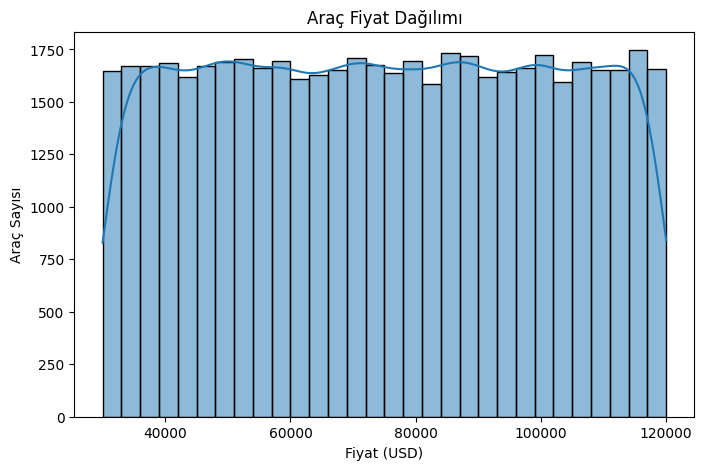

In [18]:
plt.figure(figsize=(8,5))
sns.histplot(df['Price_USD'], bins=30, kde=True)
plt.title("Araç Fiyat Dağılımı")
plt.xlabel("Fiyat (USD)")
plt.ylabel("Araç Sayısı")
plt.show()

**Araç Fiyat Dağılımı Analizi**

Araç fiyatlarının dağılımını incelemek için histogram ve KDE grafiği kullanılmıştır. Fiyatlar yaklaşık 30.000 – 120.000 USD aralığında geniş bir alana yayılmış olup, dağılım oldukça dengelidir. Histogram sütunları ve KDE eğrisi, fiyatların belirgin bir yoğunluk göstermediğini, düz ve homojen bir dağılım sergilediğini ortaya koymaktadır. Aykırı değerler göze çarpmamakta, ancak fiyat segmentleri oluşturarak detaylı analiz yapmak daha derin içgörüler sağlayabilir.

**2- Motor hacmi arttıkça fiyat artıyor mu? Bu ilişkiyi görselleştirmek için,**

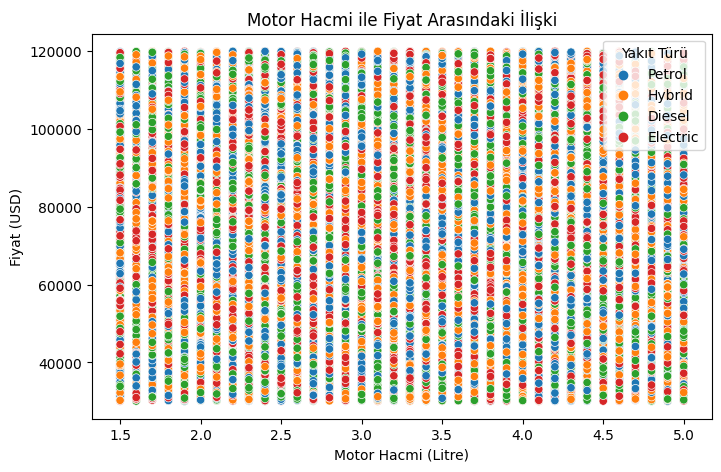

In [13]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Engine_Size_L', y='Price_USD', hue='Fuel_Type')
plt.title("Motor Hacmi ile Fiyat Arasındaki İlişki")
plt.xlabel("Motor Hacmi (Litre)")
plt.ylabel("Fiyat (USD)")
plt.legend(title="Yakıt Türü")
plt.show()

**Motor Hacmi ile Fiyat Arasındaki İlişki Analizi**

Motor hacmi ile araç fiyatı arasındaki ilişkiyi incelemek için scatterplot grafik kullanılmıştır. Motor hacmi 1.5L ile 5.0L arasında değişirken, araç fiyatları 30.000 – 120.000 USD aralığında yayılmaktadır. Grafik, motor hacmi arttıkça fiyatın belirgin şekilde yükseldiğini göstermemekte, yakıt türleri bazında da belirgin bir ayrışma gözlenmemektedir. Dolayısıyla, motor hacmi ve fiyat ilişkisini netleştirmek için korelasyon veya regresyon gibi istatistiksel analizler yapılması önerilir.

**3- Satış hacminde kategori bazlı farklılıkları (örneğin yakıt tipi) incelemek için,**

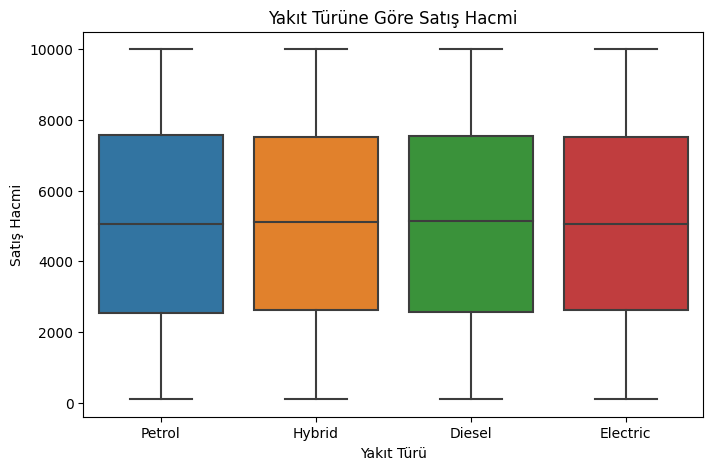

In [14]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Fuel_Type', y='Sales_Volume')
plt.title("Yakıt Türüne Göre Satış Hacmi")
plt.xlabel("Yakıt Türü")
plt.ylabel("Satış Hacmi")
plt.show()

**Yakıt Türüne Göre Satış Hacmi Analizi**

Yakıt türlerine göre satış hacmindeki farklılıkları incelemek amacıyla boxplot grafik kullanılmıştır. Petrol, Hybrid, Diesel ve Electric gruplarının satış hacmi dağılımları oldukça benzer olup, yaklaşık 0 – 10.000 aralığında değerler göstermektedir. Median değerler birbirine yakın, belirgin bir fark ya da aşırı aykırı değer gözlenmemektedir. Dolayısıyla, yakıt türleri arasında net bir satış hacmi farkı oluşmamış; ancak kesin yorum için istatistiksel testler gereklidir. Ayrıca, satış hacmini etkileyebilecek diğer faktörlerin de değerlendirilmesi yararlı olacaktır.

**4- Hangi bölgedeki araçların ortalama fiyatı daha yüksek?**

/tmp/ipykernel_36/615938073.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Region', y='Price_USD', estimator='mean', ci=None)


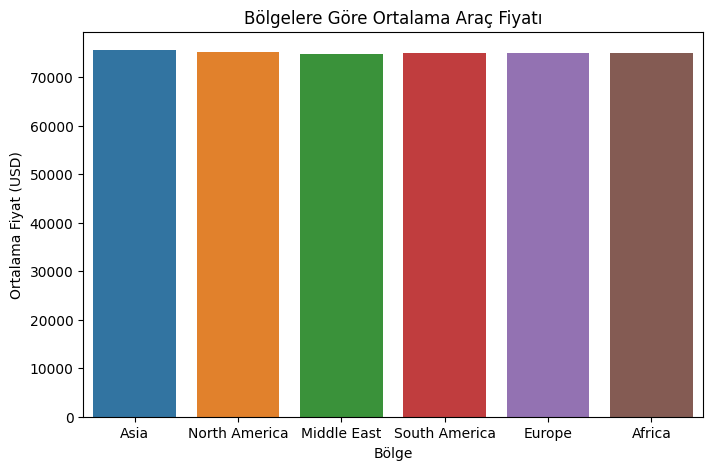

In [15]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='Region', y='Price_USD', estimator='mean', ci=None)
plt.title("Bölgelere Göre Ortalama Araç Fiyatı")
plt.xlabel("Bölge")
plt.ylabel("Ortalama Fiyat (USD)")
plt.show()

**Bölgelere Göre Ortalama Araç Fiyatı Analizi**

Hangi bölgedeki araçların ortalama fiyatının daha yüksek olduğunu incelemek için barplot grafik kullanılmıştır. Asia, North America, Middle East, South America, Europe ve Africa bölgelerinin ortalama araç fiyatları oldukça yakın olup, yaklaşık 73.000 – 75.000 USD aralığında seyretmektedir. Grafik, bölgeler arasında belirgin bir fiyat farkı olmadığını göstermektedir. Ancak küçük farkların istatistiksel olarak anlamlı olup olmadığını belirlemek için ek analizler yapılması önerilir. Fiyat analizine yakıt türü veya araç tipi gibi başka değişkenlerin de dahil edilmesi faydalı olabilir.

**5- Veri setinde hangi yakıt türü ne kadar yer kaplıyor görmek için,**

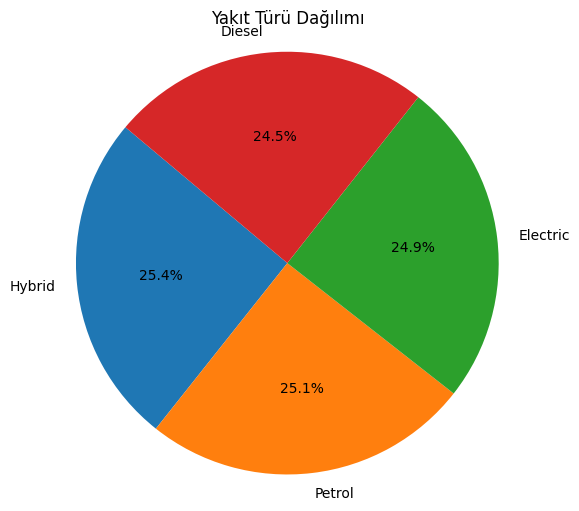

In [16]:
fuel_counts = df['Fuel_Type'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(fuel_counts, labels=fuel_counts.index, autopct='%1.1f%%', startangle=140)
plt.title("Yakıt Türü Dağılımı")
plt.axis('equal')
plt.show()

**Yakıt Türü Dağılımı Analizi**

Veri setinde yakıt türlerinin oranını göstermek için pasta grafiği kullanılmıştır. Hybrid, Petrol, Electric ve Diesel türleri sırasıyla %25.4, %25.1, %24.9 ve %24.5 oranlarında yer almakta olup, dağılım oldukça dengelidir. Yakıt türleri arasında belirgin bir fark görülmemekte, bu da yakıt türüne göre yapılacak analizler için eşit temsiliyet sağlar. Daha detaylı analizler için yakıt türüne bağlı fiyat, satış hacmi gibi değişkenlerin incelenmesi önerilir.

**6- Satış sınıflarına göre fiyat farklılıkları var mı görmek için,**

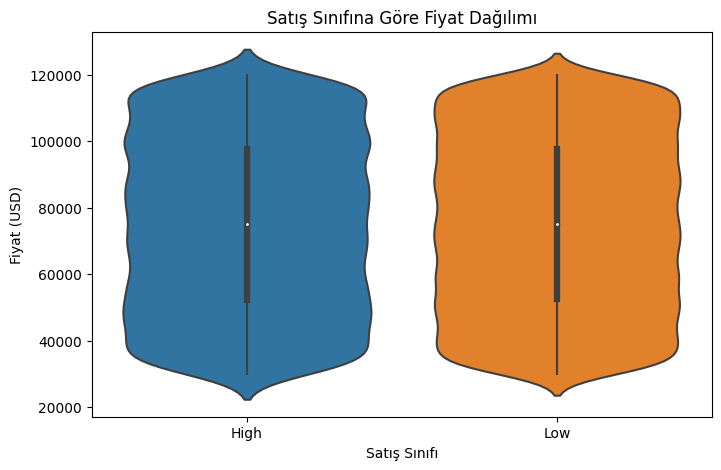

In [17]:
plt.figure(figsize=(8,5))
sns.violinplot(data=df, x='Sales_Classification', y='Price_USD')
plt.title("Satış Sınıfına Göre Fiyat Dağılımı")
plt.xlabel("Satış Sınıfı")
plt.ylabel("Fiyat (USD)")
plt.show()

**Satış Sınıflarına Göre Fiyat Analizi**

Satış sınıfına (High vs. Low) göre fiyat farklılıklarını incelemek için violin plot kullanılmıştır. Grafik sonuçlarına göre, High ve Low sınıflarının fiyat dağılımları oldukça benzer olup, her iki grup da 20.000 – 120.000 USD aralığında ve simetrik bir şekilde dağılmıştır. Median değerleri yakın, belirgin bir fark yoktur ve ciddi aykırı değerler gözlenmemektedir. Dolayısıyla, fiyat bazlı net bir sınıf ayrımı görünmemekte; kesin bir yorum için istatistiksel testlere ihtiyaç vardır. Ayrıca, ürün türü, bölge veya dönem gibi diğer değişkenlerin de incelenmesi faydalı olabilir.

# Genel Sonuç – Veri Analizi Değerlendirmesi

Yapılan analizlerde araç fiyatları, satış sınıfı, yakıt türü, motor hacmi ve bölge gibi faktörlerle birlikte incelenmiştir. Satış sınıfına göre fiyatlar benzer dağılım göstermekte; fiyat bazlı anlamlı bir ayrım bulunmamaktadır. Aynı şekilde, yakıt türlerinin satış hacmine ve veri setindeki oranlarına bakıldığında tüm gruplar dengeli temsil edilmektedir. Araç fiyatlarının genel dağılımı geniş aralığa yayılmış ve belirgin bir fiyat yoğunluğu ya da segmentasyonu gözlenmemiştir. Bölgelere göre ortalama fiyatlar arasında ise önemli farklar bulunmamakta, tüm bölgeler benzer ortalama değerlere sahiptir. Son olarak, motor hacmi ile fiyat arasında da belirgin ve güçlü bir ilişki tespit edilememiştir.

Bu analizler genel olarak, veri setinin dengeli yapıya sahip olduğunu ve incelenen değişkenler arasında gözle görülür güçlü bir ilişki bulunmadığını göstermektedir. Ancak daha net ve güvenilir yorumlar için istatistiksel testler (ANOVA, t-test, korelasyon, regresyon gibi) yapılması önerilir. Ayrıca, bu değişkenlerin bir araya getirildiği çok değişkenli analizlerle daha derin içgörüler elde edilebilir.